# 00 - Environment and CIFAR-10 data

This Stage 1 notebook records the runtime, loads CIFAR-10 from the existing extracted files or local project archive, creates three saved disjoint clean calibration/evaluation splits, prints dataset and class counts, and previews clean evaluation images. It does not download datasets, train models, or run conformal prediction.

For each split seed (42, 43, and 44), the 10,000 official CIFAR-10 test indices are independently permuted and divided into 5,000 calibration and 5,000 evaluation indices. Within each split, the subsets are disjoint and cover the full test set. Saved indices refer to official CIFAR-10 test ordering; CIFAR-10-C must reuse those canonical indices.

Expected input: extracted batches under data/raw/cifar-10-batches-py, or the existing ZIP under data/archives. This notebook does not download data.


## 1. Runtime and imports

PyTorch and torchvision support data loading and device reporting. NumPy and Python random control reproducibility; pandas displays class counts; Matplotlib displays images. This cell checks dependencies and does not install packages automatically.


In [1]:
import importlib.util
import platform
import random
import subprocess
from pathlib import Path

required_packages = ["torch", "torchvision", "numpy", "pandas", "matplotlib"]
missing_packages = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing_packages:
    raise ModuleNotFoundError(
        "Missing required packages: " + ", ".join(missing_packages)
        + ". Use Google Colab or a local Python environment with these packages installed."
    )

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision.datasets import CIFAR10

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")


Python: 3.12.10
PyTorch: 2.14.1+cu126
torchvision: 0.29.1+cu126
NumPy: 2.5.3
pandas: 3.0.6
Matplotlib: 3.11.2


## 2. Reproducibility and device selection

Seed Python, NumPy, and PyTorch. Select CUDA when available, then Intel XPU, then CPU. If an Intel graphics adapter is detected but PyTorch XPU is unavailable, print that fact clearly.


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if hasattr(torch, "xpu") and torch.xpu.is_available():
    torch.xpu.manual_seed_all(SEED)
if hasattr(torch.backends, "cudnn"):
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def detect_display_adapters():
    commands = []
    if platform.system() == "Windows":
        commands.append([
            "powershell", "-NoProfile", "-Command",
            "(Get-CimInstance Win32_VideoController | Select-Object -ExpandProperty Name) -join '; '",
        ])
    elif platform.system() == "Linux":
        commands.append(["lspci"])
    for command in commands:
        try:
            result = subprocess.run(command, capture_output=True, text=True, timeout=10, check=False)
        except (FileNotFoundError, subprocess.TimeoutExpired):
            continue
        if result.returncode == 0 and result.stdout.strip():
            return [line.strip() for line in result.stdout.splitlines() if line.strip()]
    return []


cuda_available = torch.cuda.is_available()
xpu_available = hasattr(torch, "xpu") and torch.xpu.is_available()
adapter_names = detect_display_adapters()
intel_adapter_detected = any(
    "intel" in name.lower() and any(token in name.lower() for token in ("graphics", "arc", "uhd", "iris", "xe"))
    for name in adapter_names
)

if cuda_available:
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)
elif xpu_available:
    device = torch.device("xpu")
    try:
        device_name = torch.xpu.get_device_name(0)
    except (AttributeError, RuntimeError):
        device_name = str(torch.xpu.get_device_properties(0))
else:
    device = torch.device("cpu")
    device_name = platform.processor() or platform.machine() or "CPU"

print(f"PyTorch version: {torch.__version__}")
print(f"Selected device: {device}")
print(f"CUDA available: {cuda_available}")
print(f"Intel XPU available: {xpu_available}")
print(f"Device name: {device_name}")
if adapter_names:
    print("Detected display adapters:", "; ".join(adapter_names))
if intel_adapter_detected and not xpu_available:
    print("Intel graphics detected, but PyTorch XPU is unavailable; using the selected fallback device.")


PyTorch version: 2.14.1+cu126
Selected device: cuda
CUDA available: True
Intel XPU available: False
Device name: NVIDIA GeForce MX330


## 3. Load the CIFAR-10 dataset

The notebook first uses existing extracted CIFAR-10 batches under data/raw/cifar-10-batches-py. If they are absent, it looks for the local ZIP in the project root, data/archives, or data/raw. It does not download the dataset. The archive is checked and the standard Python batch files are copied into data/raw/cifar-10-batches-py.

The 50,000 official training images are reserved for later model training. The 10,000 official test images are divided into calibration and clean evaluation subsets.


In [3]:
import shutil
import zipfile

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_ROOT = PROJECT_ROOT / "data" / "raw"
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

extracted_dir = DATA_ROOT / "cifar-10-batches-py"
required_members = [
    "cifar-10-batches-py/batches.meta",
    "cifar-10-batches-py/test_batch",
    *[f"cifar-10-batches-py/data_batch_{index}" for index in range(1, 6)],
]
if all((extracted_dir / Path(member).name).is_file() for member in required_members):
    CIFAR_ARCHIVE = None
    print(f"Using existing extracted CIFAR-10 batch files: {extracted_dir}")
else:
    archive_candidates = []
    for search_root in (PROJECT_ROOT, PROJECT_ROOT / "data" / "archives", DATA_ROOT):
        if search_root.is_dir():
            archive_candidates.extend(search_root.glob("cifar-10-batches-py*.zip"))
            archive_candidates.extend(search_root.glob("cifar10_batches_user_download.zip"))
    archive_candidates = sorted({candidate.resolve() for candidate in archive_candidates})
    if len(archive_candidates) != 1:
        raise FileNotFoundError(
            "CIFAR-10 batches are not extracted and exactly one local archive was not found. "
            "Place the ZIP in data/archives or extract it under data/raw/cifar-10-batches-py. "
            f"Found: {[str(path) for path in archive_candidates]}"
        )
    CIFAR_ARCHIVE = archive_candidates[0]
    with zipfile.ZipFile(CIFAR_ARCHIVE, "r") as archive:
        archive_members = set(archive.namelist())
        missing_members = sorted(set(required_members) - archive_members)
        if missing_members:
            raise ValueError(f"The CIFAR-10 dataset archive is missing files: {missing_members}")
        bad_member = archive.testzip()
        if bad_member is not None:
            raise ValueError(f"ZIP CRC check failed for member: {bad_member}")
        extracted_dir.mkdir(parents=True, exist_ok=True)
        for member in required_members:
            destination = extracted_dir / Path(member).name
            if not destination.is_file():
                with archive.open(member, "r") as source, destination.open("wb") as target:
                    shutil.copyfileobj(source, target)
    print(f"Extracted CIFAR-10 batch files from: {CIFAR_ARCHIVE}")

train_dataset = CIFAR10(root=str(DATA_ROOT), train=True, download=False)
test_dataset = CIFAR10(root=str(DATA_ROOT), train=False, download=False)
class_names = list(train_dataset.classes)
train_labels = np.asarray(train_dataset.targets, dtype=np.int64)
test_labels = np.asarray(test_dataset.targets, dtype=np.int64)

print(f"Training images: {len(train_dataset):,}")
print(f"Official test images: {len(test_dataset):,}")
print(f"Number of classes: {len(class_names)}")
print(f"Class names: {class_names}")
print(f"Image shape (H, W, C): {np.asarray(test_dataset[0][0]).shape}")
if CIFAR_ARCHIVE is not None:
    print(f"CIFAR-10 dataset archive: {CIFAR_ARCHIVE.name}")


Using existing extracted CIFAR-10 batch files: E:\unc\2026f\store566\final project\data\raw\cifar-10-batches-py


Training images: 50,000
Official test images: 10,000
Number of classes: 10
Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image shape (H, W, C): (32, 32, 3)


## 4. Create or load the three saved splits

For each seed in `SPLIT_SEEDS`, a seeded permutation divides test indices into calibration and evaluation subsets, each of size 5,000. Each split is saved to its own `clean_test_split_seed{seed}.npz` file. An existing file is reused rather than silently overwritten.

The disjointness and full-coverage requirements apply within each split. Different repetitions draw from the same official test set, so indices may appear in different roles across separate repetitions.


In [4]:
SPLIT_SEEDS = [42, 43, 44]
split_indices = {}

for split_seed in SPLIT_SEEDS:
    split_path = SPLIT_DIR / f"clean_test_split_seed{split_seed}.npz"
    if split_path.exists():
        with np.load(split_path) as saved:
            saved_seed = int(saved["seed"])
            calibration_for_seed = saved["calibration_indices"].astype(np.int64)
            evaluation_for_seed = saved["evaluation_indices"].astype(np.int64)
        if saved_seed != split_seed:
            raise ValueError(f"Saved split seed {saved_seed} does not match requested seed {split_seed}.")
    else:
        permutation = np.random.default_rng(split_seed).permutation(len(test_dataset))
        calibration_for_seed = permutation[: len(test_dataset) // 2].astype(np.int64)
        evaluation_for_seed = permutation[len(test_dataset) // 2 :].astype(np.int64)
        np.savez_compressed(
            split_path,
            seed=np.asarray(split_seed, dtype=np.int64),
            calibration_indices=calibration_for_seed,
            evaluation_indices=evaluation_for_seed,
        )
    split_indices[split_seed] = {
        "calibration_indices": calibration_for_seed,
        "evaluation_indices": evaluation_for_seed,
    }
    print(
        f"Seed {split_seed}: saved/loaded {split_path.name}; "
        f"calibration={len(calibration_for_seed):,}, evaluation={len(evaluation_for_seed):,}"
    )

# Keep seed 42 as the representative split for the preview below.
calibration_indices = split_indices[SEED]["calibration_indices"]
evaluation_indices = split_indices[SEED]["evaluation_indices"]


Seed 42: saved/loaded clean_test_split_seed42.npz; calibration=5,000, evaluation=5,000
Seed 43: saved/loaded clean_test_split_seed43.npz; calibration=5,000, evaluation=5,000
Seed 44: saved/loaded clean_test_split_seed44.npz; calibration=5,000, evaluation=5,000


In [5]:
assert len(train_dataset) == 50_000, f"Expected 50,000 training examples; got {len(train_dataset)}."
assert len(test_dataset) == 10_000, f"Expected 10,000 test examples; got {len(test_dataset)}."
assert train_labels.shape == (50_000,)
assert test_labels.shape == (10_000,)
assert np.asarray(test_dataset[0][0]).shape == (32, 32, 3)
assert set(np.unique(train_labels)).issubset(set(range(10)))
assert set(np.unique(test_labels)).issubset(set(range(10)))

class_count_rows = []
training_counts = np.bincount(train_labels, minlength=10)
for split_seed in SPLIT_SEEDS:
    calibration_for_seed = split_indices[split_seed]["calibration_indices"]
    evaluation_for_seed = split_indices[split_seed]["evaluation_indices"]

    assert len(calibration_for_seed) == len(evaluation_for_seed) == 5_000
    assert np.all((0 <= calibration_for_seed) & (calibration_for_seed < len(test_dataset)))
    assert np.all((0 <= evaluation_for_seed) & (evaluation_for_seed < len(test_dataset)))
    assert set(calibration_for_seed).isdisjoint(set(evaluation_for_seed)), (
        f"Calibration/evaluation overlap found for seed {split_seed}."
    )
    assert set(calibration_for_seed).union(evaluation_for_seed) == set(range(len(test_dataset))), (
        f"Split seed {split_seed} does not cover each official test index exactly once."
    )

    calibration_counts = np.bincount(test_labels[calibration_for_seed], minlength=10)
    evaluation_counts = np.bincount(test_labels[evaluation_for_seed], minlength=10)
    for class_id, class_name in enumerate(class_names):
        class_count_rows.append({
            "seed": split_seed,
            "class_id": class_id,
            "class_name": class_name,
            "training": int(training_counts[class_id]),
            "calibration": int(calibration_counts[class_id]),
            "evaluation": int(evaluation_counts[class_id]),
        })
    print(
        f"Seed {split_seed}: overlap={len(set(calibration_for_seed) & set(evaluation_for_seed))}, "
        f"union={len(set(calibration_for_seed) | set(evaluation_for_seed))}"
    )

class_counts = pd.DataFrame(class_count_rows)
display(class_counts)
print("Sanity checks passed for all three splits.")


Seed 42: overlap=0, union=10000
Seed 43: overlap=0, union=10000
Seed 44: overlap=0, union=10000


,seed,class_id,class_name,training,calibration,evaluation
0,42,0,airplane,5000,527,473
1,42,1,automobile,5000,510,490
2,42,2,bird,5000,502,498
3,42,3,cat,5000,486,514
4,42,4,deer,5000,495,505
5,42,5,dog,5000,499,501
6,42,6,frog,5000,488,512
7,42,7,horse,5000,490,510
8,42,8,ship,5000,500,500
9,42,9,truck,5000,503,497


Sanity checks passed for all three splits.


## 5. Preview evaluation images

The sample uses the saved seed-42 evaluation indices and does not change the images. Manually confirm the previews show CIFAR-10 content at native 32x32 resolution.


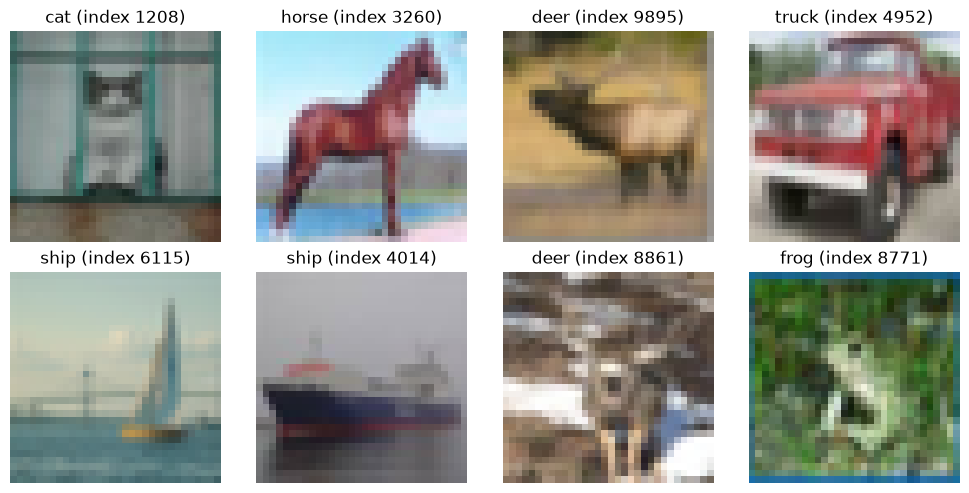

In [6]:
preview_indices = evaluation_indices[:8]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for axis, image_index in zip(axes.flat, preview_indices):
    image, label = test_dataset[int(image_index)]
    axis.imshow(image)
    axis.set_title(f"{class_names[int(label)]} (index {int(image_index)})")
    axis.axis("off")
plt.tight_layout()
plt.show()


## Stage 1 review checklist

Confirm that the environment reports the PyTorch versions and selected device; dataset sizes are 50,000 and 10,000; three split files exist for seeds 42, 43, and 44; each has 5,000 calibration and 5,000 evaluation examples with overlap 0 and union size 10,000; class counts sum to the subset sizes; and the seed-42 preview images look correct.

Do not continue to model training until this notebook runs and these checks pass.
